# Neural Network

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import optuna
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("All imports successful!")

All imports successful!


In [2]:
# Load Commercial Banks data (2 year filter)
bank_tickers = ['NABIL', 'NICA', 'HBL', 'ADBL', 'EBL', 
                'SCB', 'SBI', 'SANIMA', 'GBIME', 'NBL',
                'NIMB', 'CZBIL', 'MBL', 'PCBL', 'NMB',
                'PRVU', 'SRBL', 'LXBL', 'KBL']

dfs = []
for ticker in bank_tickers:
    try:
        df = pd.read_csv(f'../data/processed/{ticker}_features.csv')
        dfs.append(df)
    except:
        pass

data = pd.concat(dfs, ignore_index=True)
data['Date'] = pd.to_datetime(data['Date'])
data = data[data['Date'] >= pd.Timestamp('2024-01-01')]

# Define features
drop_cols = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume',
             'Trades', 'Turnover', 'Ticker', 'Label', 'Future_Return', 'Sector']
feature_cols = [c for c in data.columns if c not in drop_cols]

data = data.dropna(subset=feature_cols + ['Label'])

X = data[feature_cols].values
y = data['Label'].values

print(f"Total rows: {len(data)}")
print(f"Features: {len(feature_cols)}")
print(f"Label distribution: {pd.Series(y).value_counts().to_dict()}")

Total rows: 9656
Features: 23
Label distribution: {1: 5783, 0: 2042, 2: 1831}


In [3]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {len(X_train)} rows")
print(f"Test:  {len(X_test)} rows")

# Convert to PyTorch tensors
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.LongTensor(y_train)
X_test_t  = torch.FloatTensor(X_test)
y_test_t  = torch.LongTensor(y_test)

# DataLoader
train_ds = TensorDataset(X_train_t, y_train_t)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)

print(f"Batches per epoch: {len(train_dl)}")
print("Tensors ready!")

Train: 7724 rows
Test:  1932 rows
Batches per epoch: 61
Tensors ready!


In [4]:
# ── Optuna Hyperparameter Search ─────────────────────────────
def objective(trial):
    n_layers = trial.suggest_int('n_layers', 2, 4)
    dropout = trial.suggest_float('dropout', 0.1, 0.5)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-5, 1e-3, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])

    # Build dynamic network
    layers = []
    input_dim = X_train.shape[1]
    hidden_sizes = [256, 128, 64, 32]

    for i in range(n_layers):
        out_dim = hidden_sizes[i]
        layers.extend([
            nn.Linear(input_dim, out_dim),
            nn.BatchNorm1d(out_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        ])
        input_dim = out_dim

    layers.append(nn.Linear(input_dim, 3))
    model_trial = nn.Sequential(*layers)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model_trial.parameters(),
                           lr=lr,
                           weight_decay=weight_decay)

    train_dl_trial = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=batch_size,
        shuffle=True
    )

    # Train 30 epochs per trial
    model_trial.train()
    for epoch in range(30):
        for X_batch, y_batch in train_dl_trial:
            optimizer.zero_grad()
            loss = nn.CrossEntropyLoss()(model_trial(X_batch), y_batch)
            loss.backward()
            optimizer.step()

    # Evaluate
    model_trial.eval()
    with torch.no_grad():
        _, predicted = torch.max(model_trial(X_test_t), 1)
        acc = accuracy_score(y_test, predicted.numpy())

    return acc

print("Running Optuna (20 trials)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print(f"\nBest accuracy: {study.best_value*100:.1f}%")
print(f"Best params:   {study.best_params}")

Running Optuna (20 trials)...

Best accuracy: 64.9%
Best params:   {'n_layers': 3, 'dropout': 0.15688706267281174, 'lr': 0.004671894996516366, 'weight_decay': 0.00010369536997148044, 'batch_size': 128}


In [7]:
# ── Train Final Model with Best Params ───────────────────────
best = study.best_params

# Build best network
layers = []
input_dim = X_train.shape[1]
hidden_sizes = [256, 128, 64, 32]

for i in range(best['n_layers']):
    out_dim = hidden_sizes[i]
    layers.extend([
        nn.Linear(input_dim, out_dim),
        nn.BatchNorm1d(out_dim),
        nn.ReLU(),
        nn.Dropout(best['dropout'])
    ])
    input_dim = out_dim

layers.append(nn.Linear(input_dim, 3))
model_final = nn.Sequential(*layers)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_final.parameters(),
                       lr=best['lr'],
                       weight_decay=best['weight_decay'])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

train_dl_final = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=best['batch_size'],
    shuffle=True
)

# Train 200 epochs
epochs = 1000
train_losses = []
best_acc = 0
best_epoch = 0

for epoch in range(epochs):
    model_final.train()
    epoch_loss = 0
    for X_batch, y_batch in train_dl_final:
        optimizer.zero_grad()
        loss = criterion(model_final(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()

    avg_loss = epoch_loss / len(train_dl_final)
    train_losses.append(avg_loss)

    # Track best accuracy
    model_final.eval()
    with torch.no_grad():
        _, predicted = torch.max(model_final(X_test_t), 1)
        acc = accuracy_score(y_test, predicted.numpy())
        if acc > best_acc:
            best_acc = acc
            best_epoch = epoch + 1

    if (epoch + 1) % 40 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Acc: {acc*100:.1f}%")

print(f"\nBest accuracy: {best_acc*100:.1f}% at epoch {best_epoch}")

# Final evaluation
model_final.eval()
with torch.no_grad():
    _, predicted = torch.max(model_final(X_test_t), 1)
    preds_final = predicted.numpy()

print(f"\nFinal Accuracy: {accuracy_score(y_test, preds_final)*100:.1f}%")
print(classification_report(y_test, preds_final, target_names=['Sell', 'Hold', 'Buy']))

Epoch 40/1000 | Loss: 0.8341 | Acc: 64.7%
Epoch 80/1000 | Loss: 0.7706 | Acc: 64.3%
Epoch 120/1000 | Loss: 0.7036 | Acc: 64.4%
Epoch 160/1000 | Loss: 0.6357 | Acc: 63.8%
Epoch 200/1000 | Loss: 0.6227 | Acc: 63.8%
Epoch 240/1000 | Loss: 0.6273 | Acc: 63.6%
Epoch 280/1000 | Loss: 0.6578 | Acc: 63.6%
Epoch 320/1000 | Loss: 0.6886 | Acc: 63.5%
Epoch 360/1000 | Loss: 0.7095 | Acc: 64.5%
Epoch 400/1000 | Loss: 0.7034 | Acc: 64.0%
Epoch 440/1000 | Loss: 0.7004 | Acc: 64.4%
Epoch 480/1000 | Loss: 0.6592 | Acc: 65.0%
Epoch 520/1000 | Loss: 0.6018 | Acc: 63.6%
Epoch 560/1000 | Loss: 0.5525 | Acc: 64.7%
Epoch 600/1000 | Loss: 0.5286 | Acc: 63.2%
Epoch 640/1000 | Loss: 0.5283 | Acc: 63.6%
Epoch 680/1000 | Loss: 0.5666 | Acc: 62.0%
Epoch 720/1000 | Loss: 0.6236 | Acc: 63.2%
Epoch 760/1000 | Loss: 0.6601 | Acc: 63.5%
Epoch 800/1000 | Loss: 0.6734 | Acc: 63.7%
Epoch 840/1000 | Loss: 0.6670 | Acc: 64.3%
Epoch 880/1000 | Loss: 0.6313 | Acc: 64.3%
Epoch 920/1000 | Loss: 0.5691 | Acc: 63.4%
Epoch 960/100

In [8]:
# ── Train with Early Stopping ─────────────────────────────────
layers = []
input_dim = X_train.shape[1]
hidden_sizes = [256, 128, 64, 32]

for i in range(best['n_layers']):
    out_dim = hidden_sizes[i]
    layers.extend([
        nn.Linear(input_dim, out_dim),
        nn.BatchNorm1d(out_dim),
        nn.ReLU(),
        nn.Dropout(best['dropout'])
    ])
    input_dim = out_dim

layers.append(nn.Linear(input_dim, 3))
model_es = nn.Sequential(*layers)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_es.parameters(),
                       lr=best['lr'],
                       weight_decay=best['weight_decay'])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

train_dl_es = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=best['batch_size'],
    shuffle=True
)

# Early stopping settings
patience = 30
best_acc = 0
best_weights = None
no_improve = 0
train_losses = []

for epoch in range(1000):
    model_es.train()
    epoch_loss = 0
    for X_batch, y_batch in train_dl_es:
        optimizer.zero_grad()
        loss = criterion(model_es(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()
    train_losses.append(epoch_loss / len(train_dl_es))

    # Check accuracy
    model_es.eval()
    with torch.no_grad():
        _, predicted = torch.max(model_es(X_test_t), 1)
        acc = accuracy_score(y_test, predicted.numpy())

    if acc > best_acc:
        best_acc = acc
        best_weights = {k: v.clone() for k, v in model_es.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1} | Loss: {train_losses[-1]:.4f} | Acc: {acc*100:.1f}% | Best: {best_acc*100:.1f}%")

# Load best weights
model_es.load_state_dict(best_weights)
model_es.eval()
with torch.no_grad():
    _, predicted = torch.max(model_es(X_test_t), 1)
    preds_es = predicted.numpy()

print(f"\nFinal Best Accuracy: {best_acc*100:.1f}%")
print(classification_report(y_test, preds_es, target_names=['Sell', 'Hold', 'Buy']))

Epoch 20 | Loss: 0.8590 | Acc: 63.0% | Best: 63.6%
Epoch 40 | Loss: 0.8286 | Acc: 63.2% | Best: 64.4%
Epoch 60 | Loss: 0.8004 | Acc: 65.3% | Best: 65.3%
Epoch 80 | Loss: 0.7742 | Acc: 65.2% | Best: 65.6%
Epoch 100 | Loss: 0.7358 | Acc: 66.0% | Best: 66.0%
Epoch 120 | Loss: 0.7048 | Acc: 64.4% | Best: 66.0%
Early stopping at epoch 130

Final Best Accuracy: 66.0%
              precision    recall  f1-score   support

        Sell       0.63      0.29      0.40       409
        Hold       0.68      0.90      0.78      1157
         Buy       0.52      0.30      0.38       366

    accuracy                           0.66      1932
   macro avg       0.61      0.50      0.52      1932
weighted avg       0.64      0.66      0.62      1932



# Logistic Regression

In [9]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
lr_acc = accuracy_score(y_test, lr_preds)

print(f"Logistic Regression Accuracy: {lr_acc*100:.1f}%")
print(classification_report(y_test, lr_preds, target_names=['Sell', 'Hold', 'Buy']))

Logistic Regression Accuracy: 60.9%
              precision    recall  f1-score   support

        Sell       0.41      0.16      0.23       409
        Hold       0.63      0.95      0.76      1157
         Buy       0.38      0.03      0.06       366

    accuracy                           0.61      1932
   macro avg       0.47      0.38      0.35      1932
weighted avg       0.54      0.61      0.51      1932



# XGBoost

In [10]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss',
    verbosity=0
)

xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_preds)

print(f"XGBoost Accuracy: {xgb_acc*100:.1f}%")
print(classification_report(y_test, xgb_preds, target_names=['Sell', 'Hold', 'Buy']))

XGBoost Accuracy: 64.8%
              precision    recall  f1-score   support

        Sell       0.56      0.27      0.37       409
        Hold       0.67      0.90      0.77      1157
         Buy       0.52      0.27      0.35       366

    accuracy                           0.65      1932
   macro avg       0.59      0.48      0.50      1932
weighted avg       0.62      0.65      0.61      1932



# LSTm 

In [11]:
# ── LSTM Model ───────────────────────────────────────────────
# LSTM needs 3D input: (samples, timesteps, features)
# We'll use 10 days as sequence length

SEQ_LEN = 10

def create_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(len(X) - seq_len):
        Xs.append(X[i:i+seq_len])
        ys.append(y[i+seq_len])
    return np.array(Xs), np.array(ys)

# Create sequences
X_seq, y_seq = create_sequences(X_scaled, y, SEQ_LEN)
print(f"Sequence shape: {X_seq.shape}")  # (samples, 10, 23)

# Train/test split
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_seq, y_seq, test_size=0.2, random_state=42, stratify=y_seq
)

# Convert to tensors
X_train_lstm = torch.FloatTensor(X_train_seq)
y_train_lstm = torch.LongTensor(y_train_seq)
X_test_lstm  = torch.FloatTensor(X_test_seq)
y_test_lstm  = torch.LongTensor(y_test_seq)

train_dl_lstm = DataLoader(
    TensorDataset(X_train_lstm, y_train_lstm),
    batch_size=128, shuffle=True
)

print(f"Train: {len(X_train_seq)} | Test: {len(X_test_seq)}")

Sequence shape: (9646, 10, 23)
Train: 7716 | Test: 1930


In [12]:
# ── LSTM Architecture ─────────────────────────────────────────
class StockLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=2, dropout=0.3):
        super(StockLSTM, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 3)
        )

    def forward(self, x):
        # x shape: (batch, seq_len, features)
        lstm_out, _ = self.lstm(x)
        # Take last timestep output
        last_out = lstm_out[:, -1, :]
        return self.classifier(last_out)

# ── Train LSTM ────────────────────────────────────────────────
lstm_model = StockLSTM(input_dim=X_seq.shape[2])
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(lstm_model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

# Early stopping
patience = 30
best_acc_lstm = 0
best_weights_lstm = None
no_improve = 0

for epoch in range(1000):
    lstm_model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_dl_lstm:
        optimizer.zero_grad()
        loss = criterion(lstm_model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()

    # Evaluate
    lstm_model.eval()
    with torch.no_grad():
        _, predicted = torch.max(lstm_model(X_test_lstm), 1)
        acc = accuracy_score(y_test_lstm, predicted.numpy())

    if acc > best_acc_lstm:
        best_acc_lstm = acc
        best_weights_lstm = {k: v.clone() for k, v in lstm_model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    if no_improve >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1} | Loss: {epoch_loss/len(train_dl_lstm):.4f} | Acc: {acc*100:.1f}% | Best: {best_acc_lstm*100:.1f}%")

# Load best weights
lstm_model.load_state_dict(best_weights_lstm)
lstm_model.eval()
with torch.no_grad():
    _, predicted = torch.max(lstm_model(X_test_lstm), 1)
    lstm_preds = predicted.numpy()

print(f"\nLSTM Best Accuracy: {best_acc_lstm*100:.1f}%")
print(classification_report(y_test_lstm, lstm_preds, target_names=['Sell', 'Hold', 'Buy']))

Epoch 20 | Loss: 0.8707 | Acc: 62.2% | Best: 62.2%
Epoch 40 | Loss: 0.7660 | Acc: 64.1% | Best: 64.4%
Epoch 60 | Loss: 0.5782 | Acc: 64.7% | Best: 65.9%
Epoch 80 | Loss: 0.4533 | Acc: 63.3% | Best: 65.9%
Early stopping at epoch 81

LSTM Best Accuracy: 65.9%
              precision    recall  f1-score   support

        Sell       0.52      0.34      0.41       408
        Hold       0.69      0.87      0.77      1156
         Buy       0.61      0.34      0.44       366

    accuracy                           0.66      1930
   macro avg       0.61      0.52      0.54      1930
weighted avg       0.64      0.66      0.63      1930



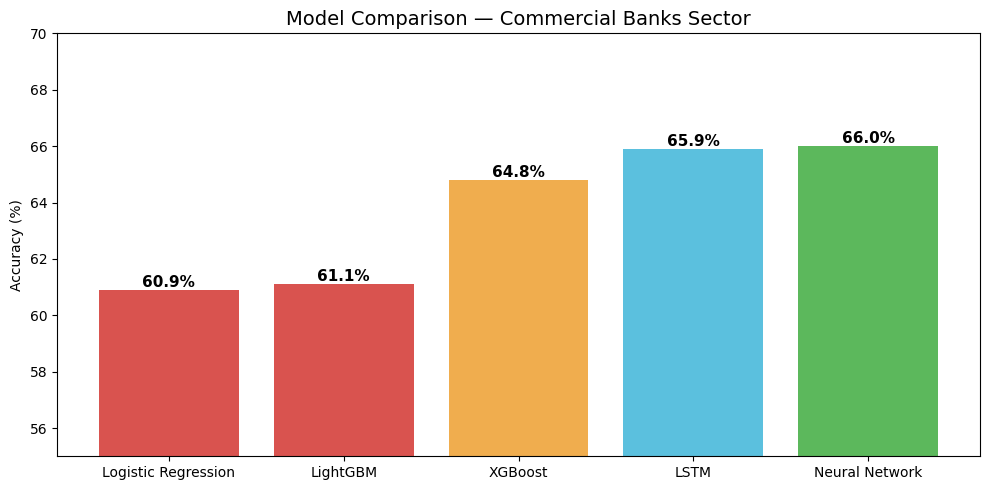

In [13]:
# ── Model Comparison Summary ─────────────────────────────────
results = {
    'Logistic Regression': 60.9,
    'LightGBM':            61.1,
    'XGBoost':             64.8,
    'LSTM':                65.9,
    'Neural Network':      66.0,
}

plt.figure(figsize=(10, 5))
colors = ['#d9534f', '#d9534f', '#f0ad4e', '#5bc0de', '#5cb85c']
bars = plt.bar(results.keys(), results.values(), color=colors)
plt.title('Model Comparison — Commercial Banks Sector', fontsize=14)
plt.ylabel('Accuracy (%)')
plt.ylim(55, 70)
for bar, val in zip(bars, results.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{val}%', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()